# Selected chunk lengths

Compare the masks recorded by [03_02](03_02_measure_latency.ipynb) at a requested
row budget. Read `cases.csv` and `environment.json`. Paper contributes its recorded
mask, including underfilled budgets.

In [1]:
from math    import ceil
from pathlib import Path

import json

import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt

## 1. Data

A chunk is a maximal contiguous run of selected rows, stored as `[start, end)`.
Its length is `end - start` rows. Adjacent selected tiles merge, so chunk lengths
can differ from tile widths.

In [2]:
PAPER = "Paper greedy (GPU sort)"

results     = pd.read_csv("cases.csv", float_precision="round_trip")
environment = json.loads(Path("environment.json").read_text())

In [3]:
results = results.rename(columns={"tile_rows": "tile_width"})
results["intervals"] = results.intervals.map(json.loads)

# Profile boundary: KiB -> rows.
row_kib  = results.d * environment["dtype_bytes"] / 1024
boundary = environment["tile_boundary_kib"]
results["saturation_rows"] = boundary / row_kib

In [4]:
# One record per trace, method, and requested budget within each shape.
assert not results.duplicated(["n", "d", "method", "fraction", "trace_id"]).any()

## 2. Chunk counts

For each method and requested budget, divide each bin's total chunk count by
the number of traces. Empty masks contribute zero counts and remain in the
denominator. Histogram heights sum to the mean chunks per trace.

Within each shape, check that methods use the same traces and budgets.

In [5]:
class ChunkLengths:
    def __init__(self, rows):
        self.trace_ids   = pd.Index(rows.trace_id).sort_values()
        self.trace_count = len(self.trace_ids)  # Include empty masks.

        lengths = []

        for intervals in rows.intervals:
            for start, end in intervals:
                lengths.append(end - start)

        self.lengths = np.asarray(lengths, dtype=int)

    def histogram(self, bins):
        counts, edges = np.histogram(self.lengths, bins=bins)
        return counts / self.trace_count

In [6]:
class MethodResults:
    def __init__(self, rows):
        self.tile_width = rows.tile_width.iloc[0]
        self.budgets    = {}

        for fraction, group in rows.groupby("fraction"):
            self.budgets[fraction] = ChunkLengths(group)

    def assert_comparable_to(self, baseline):
        assert self.budgets.keys() == baseline.budgets.keys()

        for fraction, group in self.budgets.items():
            current_index  = group.trace_ids
            baseline_index = baseline.budgets[fraction].trace_ids

            assert current_index.equals(baseline_index)

In [7]:
class ShapeResults:
    def __init__(self, shape, rows):
        self.shape           = shape
        self.saturation_rows = rows.saturation_rows.iloc[0]
        self.trace_count     = rows.trace_id.nunique()

        # Baselines, then decreasing tile width
        groups = rows.groupby("method")

        widths = groups.tile_width.first()
        widths = widths.sort_values(
            ascending   = False,
            na_position = "first",
        )

        self.methods = {}

        for name in widths.index:
            method_rows = groups.get_group(name)
            self.methods[name] = MethodResults(method_rows)

In [8]:
chunks = {}

for shape, rows in results.groupby(["n", "d"]):
    chunks[shape] = ShapeResults(shape, rows)

In [9]:
chunks[(896, 896)].methods[PAPER].budgets[0.5].lengths[:10]

array([ 92,   8, 348, 240, 204,   4, 200,   4, 196,  48])

In [10]:
# Matched budgets and traces
for result in chunks.values():
    baseline = result.methods[PAPER]

    for method in result.methods.values():
        method.assert_comparable_to(baseline)

## 3. Plot

Set `FRACTION` and rerun the final two cells to change the displayed budget.
Within each shape, bins use half-integer edges derived from a logarithmic grid
and remain fixed across methods and budgets. All panels share axis ranges.

The x axis is logarithmic. The y axis is linear up to one chunk per trace and
logarithmic above. The dashed line marks the saved profile size with the lowest
cost per KiB, converted to rows.

In [11]:
color_scale = plt.cm.ScalarMappable(
    norm = plt.Normalize(results.fraction.min(), results.fraction.max()),
    cmap = "viridis",
)

In [12]:
def create_panels(count, ncols=4):
    nrows = ceil(count / ncols)

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize = (4 * ncols, 3 * nrows),
        sharex  = True,
        sharey  = True,
        squeeze = False,
        layout  = "constrained",
    )

    axes = axes.flatten()

    for ax in axes[count:]:
        fig.delaxes(ax)

    return fig, axes[:count]

In [13]:
def draw_method(ax, method, fraction, bins):
    group  = method.budgets[fraction]
    counts = group.histogram(bins)

    ax.stairs(
        counts, bins,
        color     = color_scale.to_rgba(fraction),
        fill      = True,
        alpha     = 0.8,
        linewidth = 0.8,
    )

In [14]:
def draw_shape(result, fraction):
    n, d    = result.shape
    s       = result.saturation_rows
    methods = result.methods

    # Half-integer edges around integer chunk lengths.
    bins = np.geomspace(1, n + 1, 33)
    bins = np.unique(bins.round()) - 0.5

    fig, axes = create_panels(len(methods))

    for ax, (name, method) in zip(axes, methods.items()):
        draw_method(ax, method, fraction, bins)

        ax.axvline(
            s,
            color     = "gray",
            linestyle = "--",
            linewidth = 1.2,
        )

        title = name
        if pd.notna(method.tile_width):
            title += f"\nB = {method.tile_width:g}"

        ax.set(
            title  = title,
            xscale = "log",
            xlim   = (bins[0], bins[-1]),
        )
        ax.set_yscale("symlog", linthresh=1)

    # Include every method before fixing the shared lower limit.
    axes[0].set_ylim(bottom=0)

    fig.supxlabel("Chunk length (rows)")
    fig.supylabel("Mean chunks per trace per bin")

    title    = f"{n} x {d} · {fraction:.0%} requested · {result.trace_count} traces"
    subtitle = f"Dashed line: s = {s:.2f} rows · Shared bins and axes"
    scale    = "Y axis: linear up to 1 chunk per trace, logarithmic above"
    fig.suptitle(f"{title}\n{subtitle}\n{scale}")
    return fig

In [15]:
FRACTION = 0.5

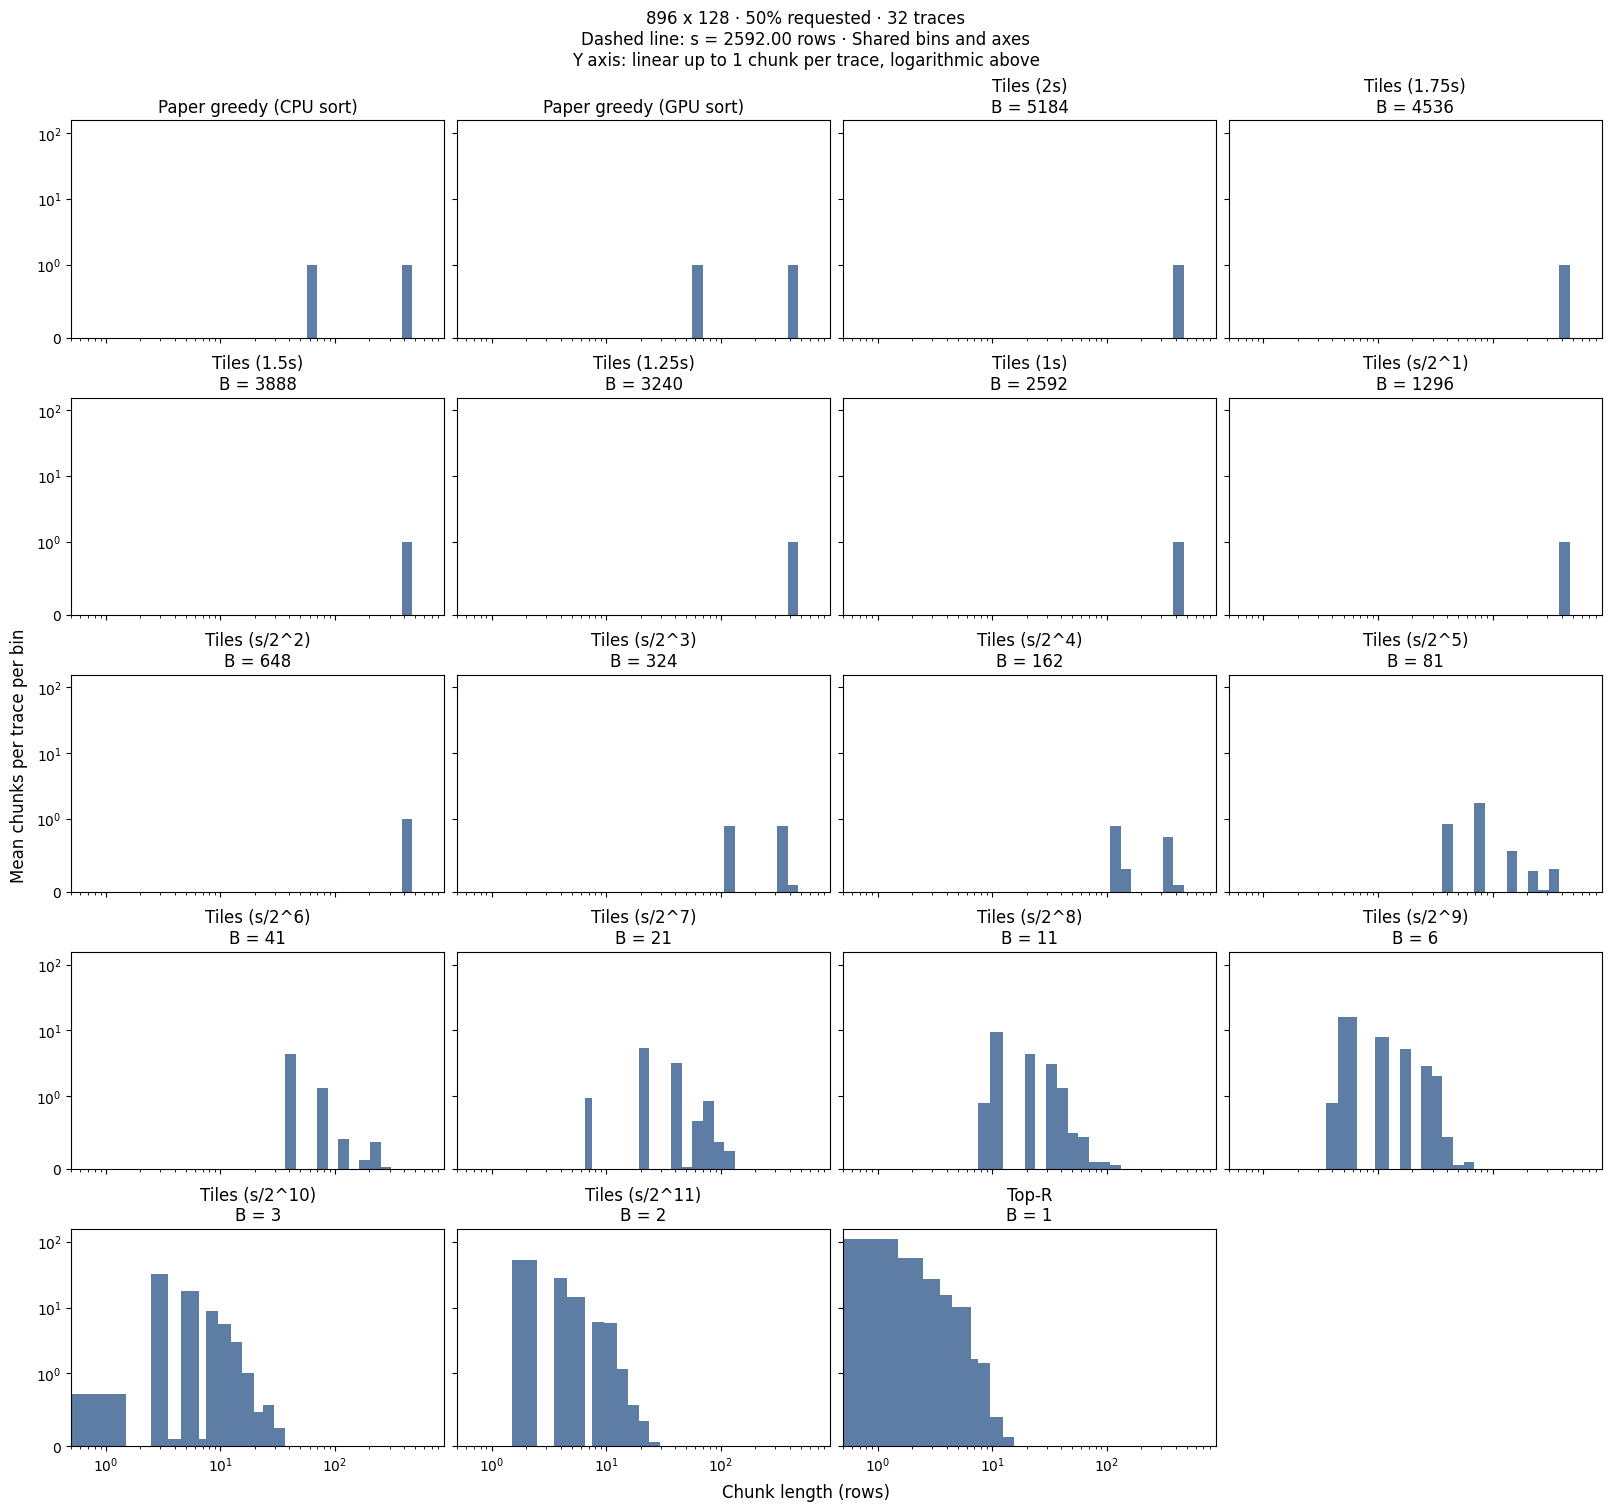

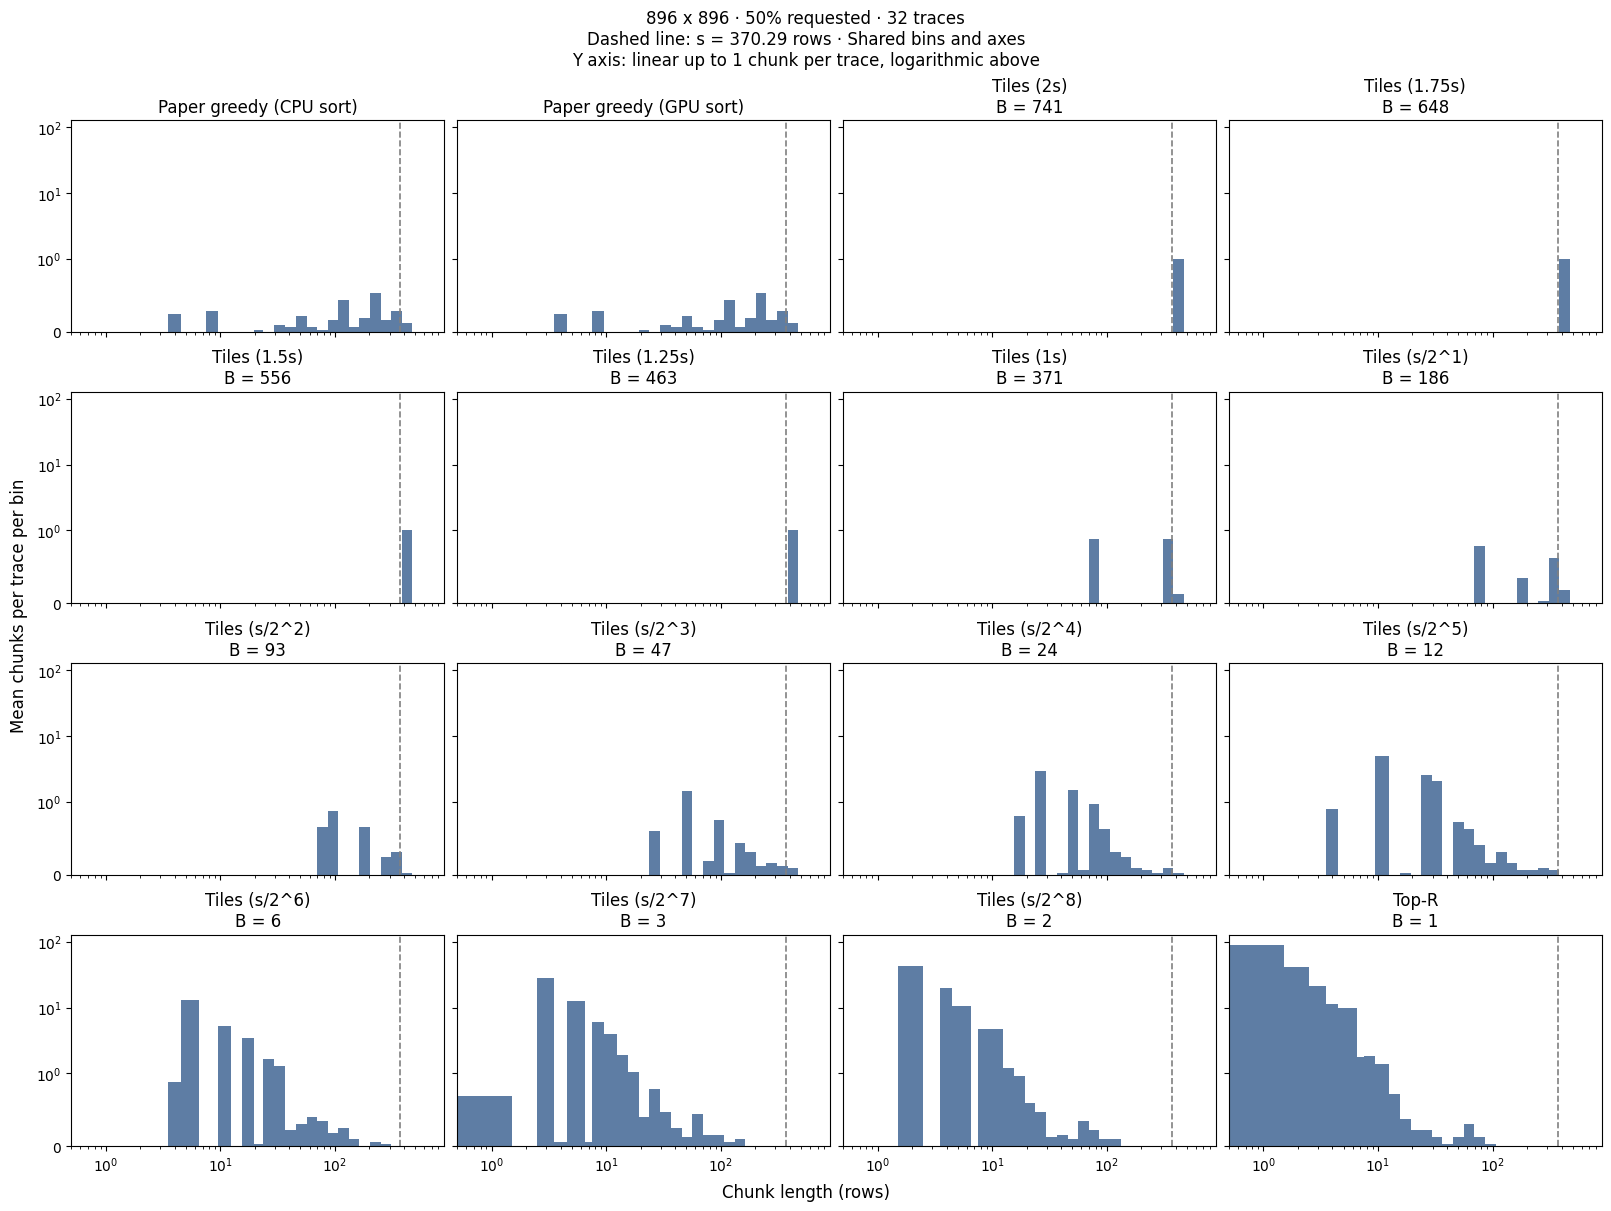

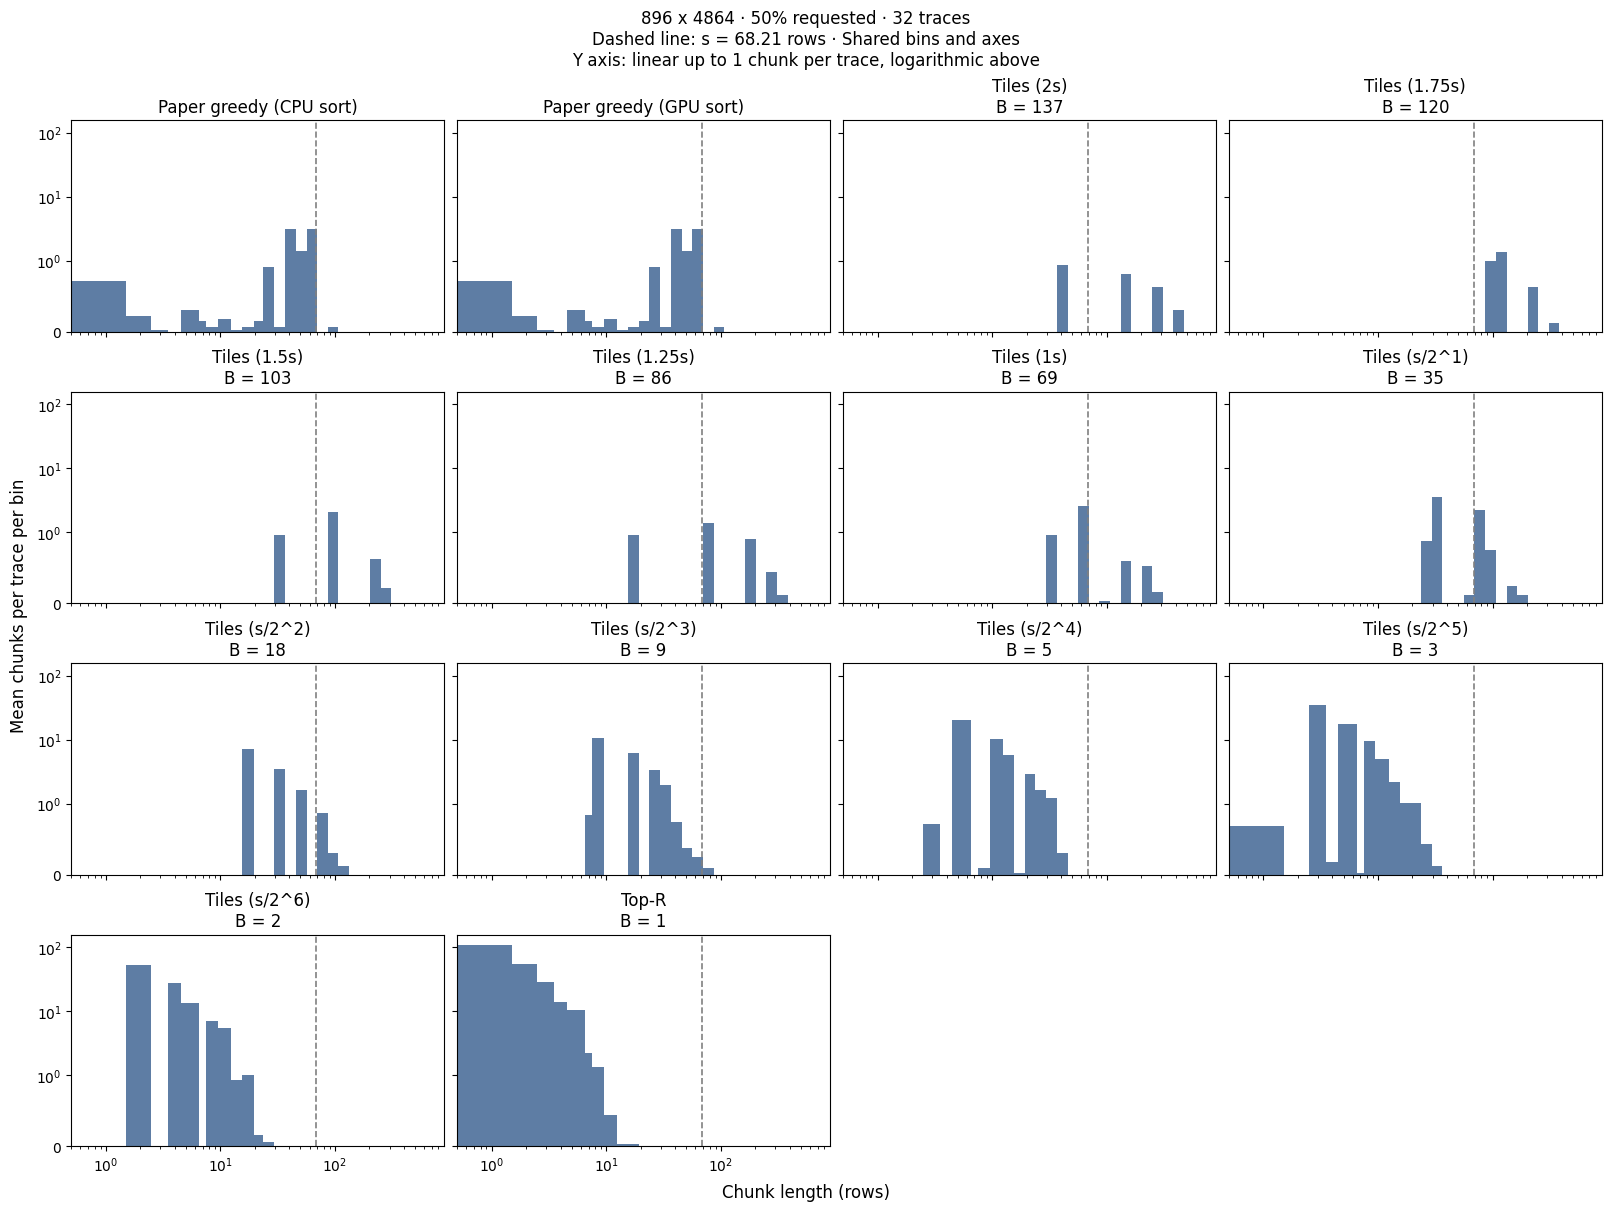

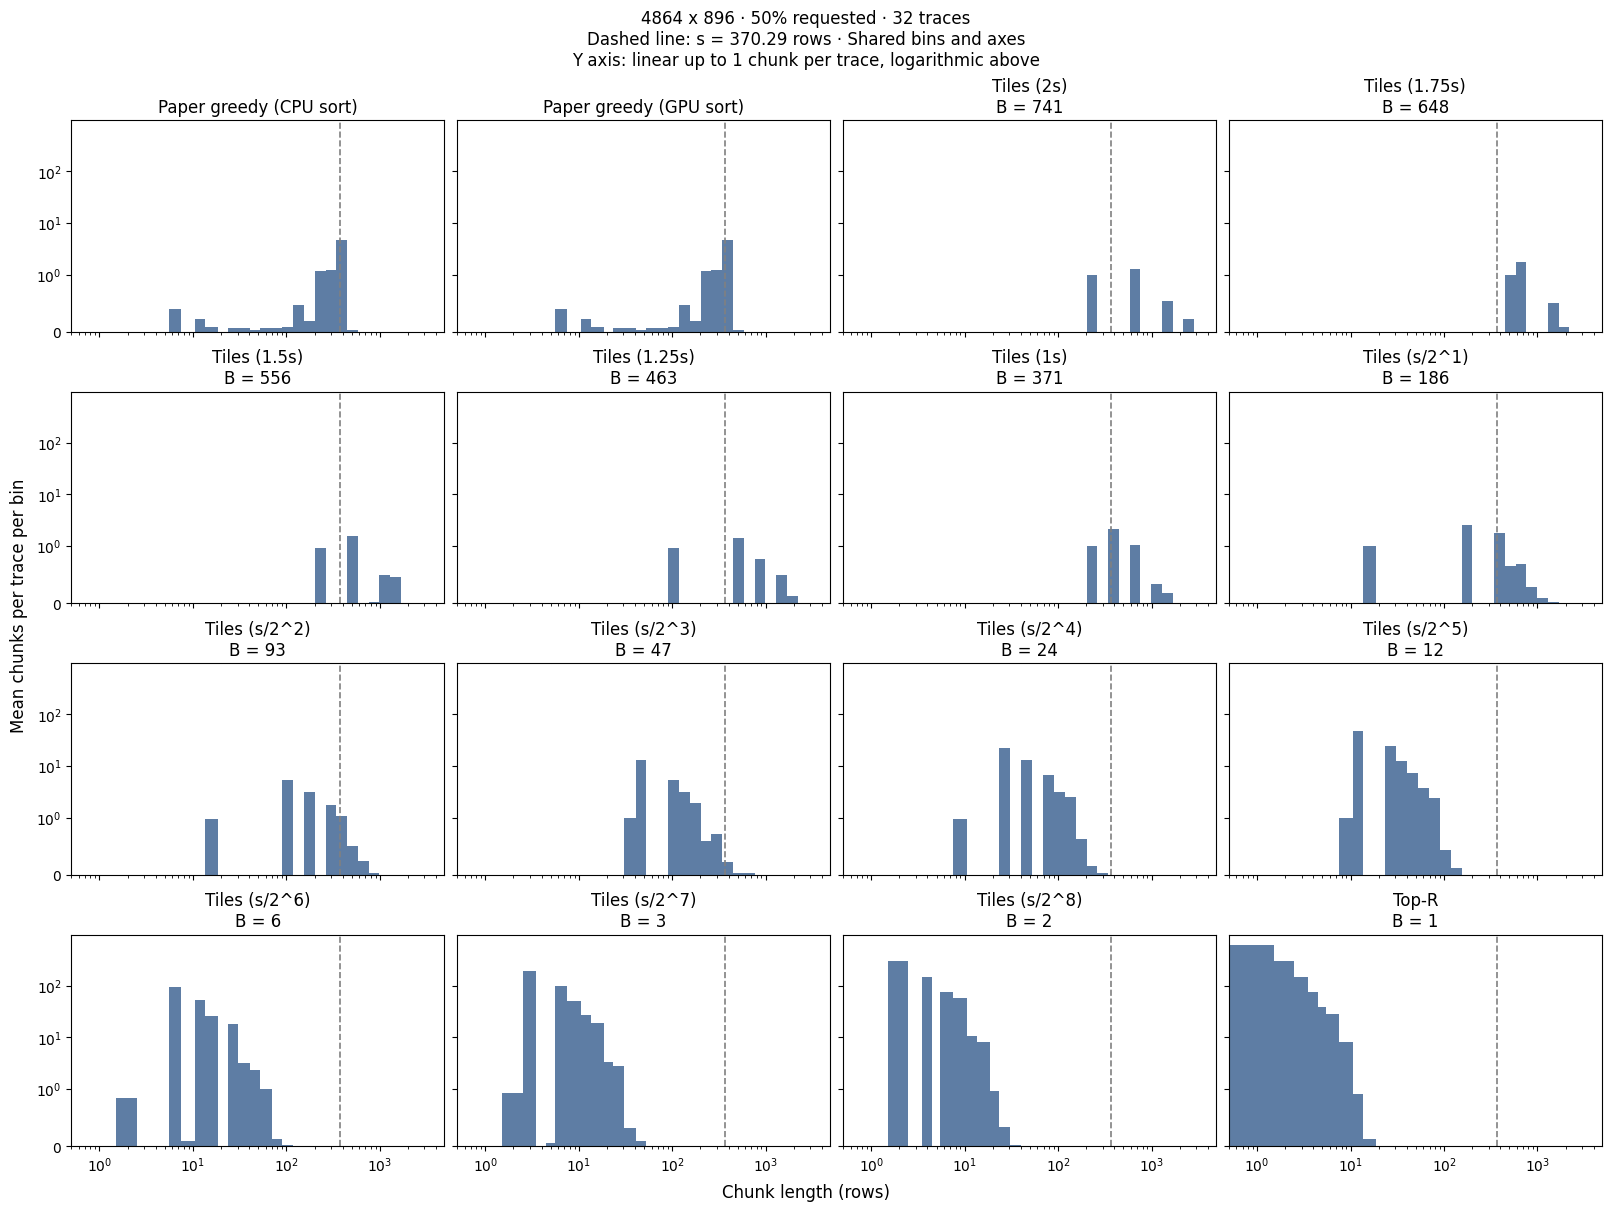

In [16]:
for result in chunks.values():
    fig = draw_shape(result, FRACTION)

    plt.show()
    plt.close(fig)